In [21]:
import pandas
import os
import matplotlib.pyplot as plt
import spglib
from collections import Counter
from pymatgen.symmetry.groups import SpaceGroup
from collections import OrderedDict
import numpy

### Scan RRUFF

In [2]:
dir = "C:\\Users\\egf3\\Downloads\\DIF"

i = 0
names = []
minerals = []
path = []
spacegroup = []
cell_params = []
wavelength = []
amount = len(os.listdir(dir))
for fileName in os.listdir(dir):
    filePath = os.path.join(dir,fileName)
    with open(filePath, 'r', encoding='latin-1') as file:
        p = 0
        w = 0
        bol = True
        for line in file:
            line = line.strip()
            if "SPACE GROUP" in line:
                #print(line)
                p+=1
                nm = (fileName.replace(".txt","").replace("C:\\Users\\egf3\\Downloads\\DIF\\",""))
                #print(line.replace("SPACE GROUP: ",""))
                sg = line.replace("SPACE GROUP: ","").replace("ALTERNATE SETTING FOR","").replace("\\par","").replace(" ","").strip()
            #if "SPACE GROUP #" in line:
             #   bol = False
            if("X-RAY WAVELENGTH:" in line):
                w+=1
                names.append(nm)
                spacegroup.append(sg)
                minerals.append(nm[0:nm.find("__")])
                wavelength.append(line.replace("X-RAY WAVELENGTH:","").strip())
                cell_params.append(celparam)
            if("X-RAY WAVELENGTHS:" in line):
                w+=1
                #print(f"Multi Wavelength Found?: {filePath}")
                names.append(nm)
                spacegroup.append(sg)
                minerals.append(nm[0:nm.find("__")])
                wavelength.append(line.replace("X-RAY WAVELENGTHS:","").strip())
                cell_params.append(celparam)
            if("CELL PARAMETERS:" in line):
                celparam = (line.replace("CELL PARAMETERS:","").strip())

        if p > 1:
            print(f"Muliple SG found in {filePath}")
        if w > 1:
            print(f"Multiple wavelengths found in {filePath}")

In [3]:
with open("RRUFF Files",'w') as file:
    for i in Counter(minerals).keys():
        file.write(f"{i}, {Counter(minerals).get(i)}")
        file.write('\n')

### Discovering Amount of Non-Standard SG

In [4]:
#two assumptions:
# "SPACE GROUP: P3        \\par" -> "P3"
# "SPACE GROUP: ALTERNATE SETTING FOR Pnmm" -> "Pnmm"

#strnage files: "I4_1/amd"

#accpetned wavelenghts: anything 1.54, ex: 1.541838,1.544390,1.540562  
#0.710730': 13

In [5]:
from collections import Counter
counts = Counter(spacegroup)
#plt.figure(figsize=(20,10))
#plt.bar(range(len(counts)), list(counts.values()), align='center')
#plt.plot()

In [6]:
df = pandas.read_csv("UPDATED_Space_Groups.csv")
mapping_csv = dict(zip(df['Symbol'], df['SG#']))


In [7]:
# Your frequency dictionary (abbreviated here for clarity)
nonstd_counts = OrderedDict(Counter(spacegroup))

symbol_to_itnum = {}
unresolved = []

# First pass – let pymatgen handle everything it recognises.
for sym in nonstd_counts:
    try:
        pmgSG = SpaceGroup(sym).int_number
        try:
            csvSG = mapping_csv[sym]
        except:
            csvSG = -1
        if(csvSG == -1 or pmgSG == csvSG):
            symbol_to_itnum[sym] = pmgSG
        else:
            print(f'CSV and PMG Mismatch: {sym} | PMG:{pmgSG} | CSV:{csvSG}')
    except ValueError:
        # pymatgen didn’t understand the string exactly as written
        unresolved.append(sym)


c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol Pbnm instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol C-1 instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol C1 instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol Amma instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\mont

In [8]:

# Second pass – quick normalisation tricks that often fix typos /
# non‑standard settings (e.g. dropping underscores, spaces, origin choice).
def _tidy(s):
    return (
        s.replace('_', ' ')      # “P2_1/a” -> “P2 1/a” (sometimes helps)
         .replace(' ', '')       # remove spaces
         .replace('−', '-')      # be sure we’re using ASCII minus
    )

for sym in unresolved[:]:
    try:
        symbol_to_itnum[sym] = SpaceGroup(_tidy(sym)).int_number
        unresolved.remove(sym)
    except ValueError:
        pass

In [ ]:


# Third pass – *manual* “hard‑cases”.
# These are legitimate but non‑standard axial settings
# that any library will choke on.  Add to taste.
manual_map = {
    "A-1": 2, "C-1": 2, "I-1": 2,                 # centred -1 settings → P -1 (#2)
    "P2_1/b": 14, "P2/a": 14, "I2/a": 15,         # monoclinic non‑unique b/c settings
    "Pbnm": 62, "Pnmn": 62, "Pn2_1m": 31,         # orthorhombic setting swaps
    "Im3": 204, "Im3m": 229, "Fd3": 203,          # cubic w/out glide n/m
    "Fd2d": 43, "Ia3": 206, "Ia3d": 230,
    "P2_1/a":14, # double check 
    "P2_1/n": 14, # double check
    "Fd3m": 227, #dc: https://stevedutch.net/symmetry/3dspacegrps/3dspgr227-228.htm
    "Fm3m":225, #double check, assuming forget bar over 3
    "Pa3":205, #assuming bar over a forget bar over 3 Pa-3
    "A2/a":15,#tables
    230
    # … extend this dict when you encounter others
}
for sym, num in manual_map.items():
    if sym in unresolved:                       # only overwrite if still missing
        symbol_to_itnum[sym] = num
        unresolved.remove(sym)


In [10]:
# ----------------------------------------------------------------------------
#   Finished mapping
# ----------------------------------------------------------------------------
print(f"Resolved {len(symbol_to_itnum)} of {len(nonstd_counts)} symbols.")
if unresolved:
    print("The following labels still need human attention:", unresolved)

# At this point `symbol_to_itnum` is what you asked for:
#    e.g.  {'P2_1/a': 14, 'P2_1/n': 14, 'Pbnm': 62, …}
# If you like, merge it straight back into your frequency dict:
itnum_counts = {symbol_to_itnum[k]: v for k, v in nonstd_counts.items()}


Resolved 186 of 218 symbols.
The following labels still need human attention: ['P2_1/n', 'Fm3m', 'P2/n', 'P2_1/a', 'Pa3', 'I2', 'Fd3c', 'A2/a', 'Fd3m', 'Pm3m', 'Ia', 'Pn3', 'B2/b', 'I2/c', 'B2_1', 'Bba2', 'Pn3m', 'Acam', 'Cmca', 'I2/m', 'Bbcm', 'Abma', 'A2/m', 'SPACEGROUP#:0', 'A2', 'Pm3n', 'Pa', 'F2/d', 'Pn', 'Aa', 'F2/m', 'Ccmb']


KeyError: 'P2_1/n'

### Creating RRUFF Dataframe & Convering SG 

In [11]:
#Check to make sure we have enough values
len(cell_params) == len(wavelength) == len(names) == len(spacegroup)

True

In [12]:
# Split up cell parametres
tempNames = names
tempspacegroup = spacegroup
tempWavelength = wavelength
tempCellParmas = cell_params
a = []
b = []
c =[] 
alpha = []
beta =[]
gamma = []

indices_to_remove = []
for (i,x) in enumerate(cell_params):
    splits = x.split()
    try:
        A = float(splits[0].replace("\\par",""))
        B = float(splits[1].replace("\\par",""))
        C = float(splits[2].replace("\\par",""))
        alp = float(splits[3].replace("\\par",""))
        bet = float(splits[4].replace("\\par",""))
        gam = float(splits[5].replace("\\par",""))
    except:
        print(f"Bad Split: {i}")
        indices_to_remove.append(i)
        continue
    
    a.append(A)
    b.append(B)
    c.append(C)
    alpha.append(alp)
    beta.append(bet)
    gamma.append(gam)
    
for idx in sorted(indices_to_remove, reverse=True):
    del tempNames[idx]
    del tempspacegroup[idx]
    del tempWavelength[idx]
    del tempCellParmas[idx]

print(len(tempNames), len(tempspacegroup), len(tempWavelength), len(a), len(b), len(c), len(alpha), len(beta), len(gamma))

Bad Split: 1687
2897 2897 2897 2897 2897 2897 2897 2897 2897


In [13]:
RRUFF_df = pandas.DataFrame({"Name":names,"Space Group Symbol":spacegroup,
                             "Wavelength":wavelength,
                             "a":a,"b":b,"c":c,
                             "alpha":alpha,"beta":beta,"gamma":gamma})

In [17]:
failCounter=0
spg = []
def _tidy(s):
    return (
        s.replace('_', ' ')# “P2_1/a” -> “P2 1/a” (sometimes helps)
         .replace(' ', '')# remove spaces
         .replace('−', '-')# be sure we’re using ASCII minus
    )
for idx,row in RRUFF_df.iterrows():
    try:
        pmgSG = SpaceGroup(row['Space Group Symbol']).int_number
    except ValueError:
        try:
            pmgSG = SpaceGroup(_tidy(sym)).int_number
        except ValueError:
            pmgSG = None    
        failCounter+=1
    spg.append(pmgSG)
print(failCounter)
failCounter = failCounter    

c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol Pbnm instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol C-1 instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol C1 instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\monty\design_patterns.py:81: UserWarning: Full symbol not available, falling back to short Hermann Mauguin symbol Amma instead
  orig_init(instance, *args, **kwargs)
c:\Users\egf3\AppData\Local\miniconda3\envs\DATA\Lib\site-packages\mont

439


In [ ]:
RRUFF_df['Space Group #'] = spg

In [27]:
standardNames = []
standardSG_Num = []
testCounter = 0
for index,row in RRUFF_df.iterrows():
    if(not numpy.isnan(row['Space Group #'])):
        standardNames.append(row["Name"])
        standardSG_Num.append(row['Space Group #'])
    else:
        testCounter+=1
assert(testCounter == failCounter)


Text(0.5, 0, 'Space Group')

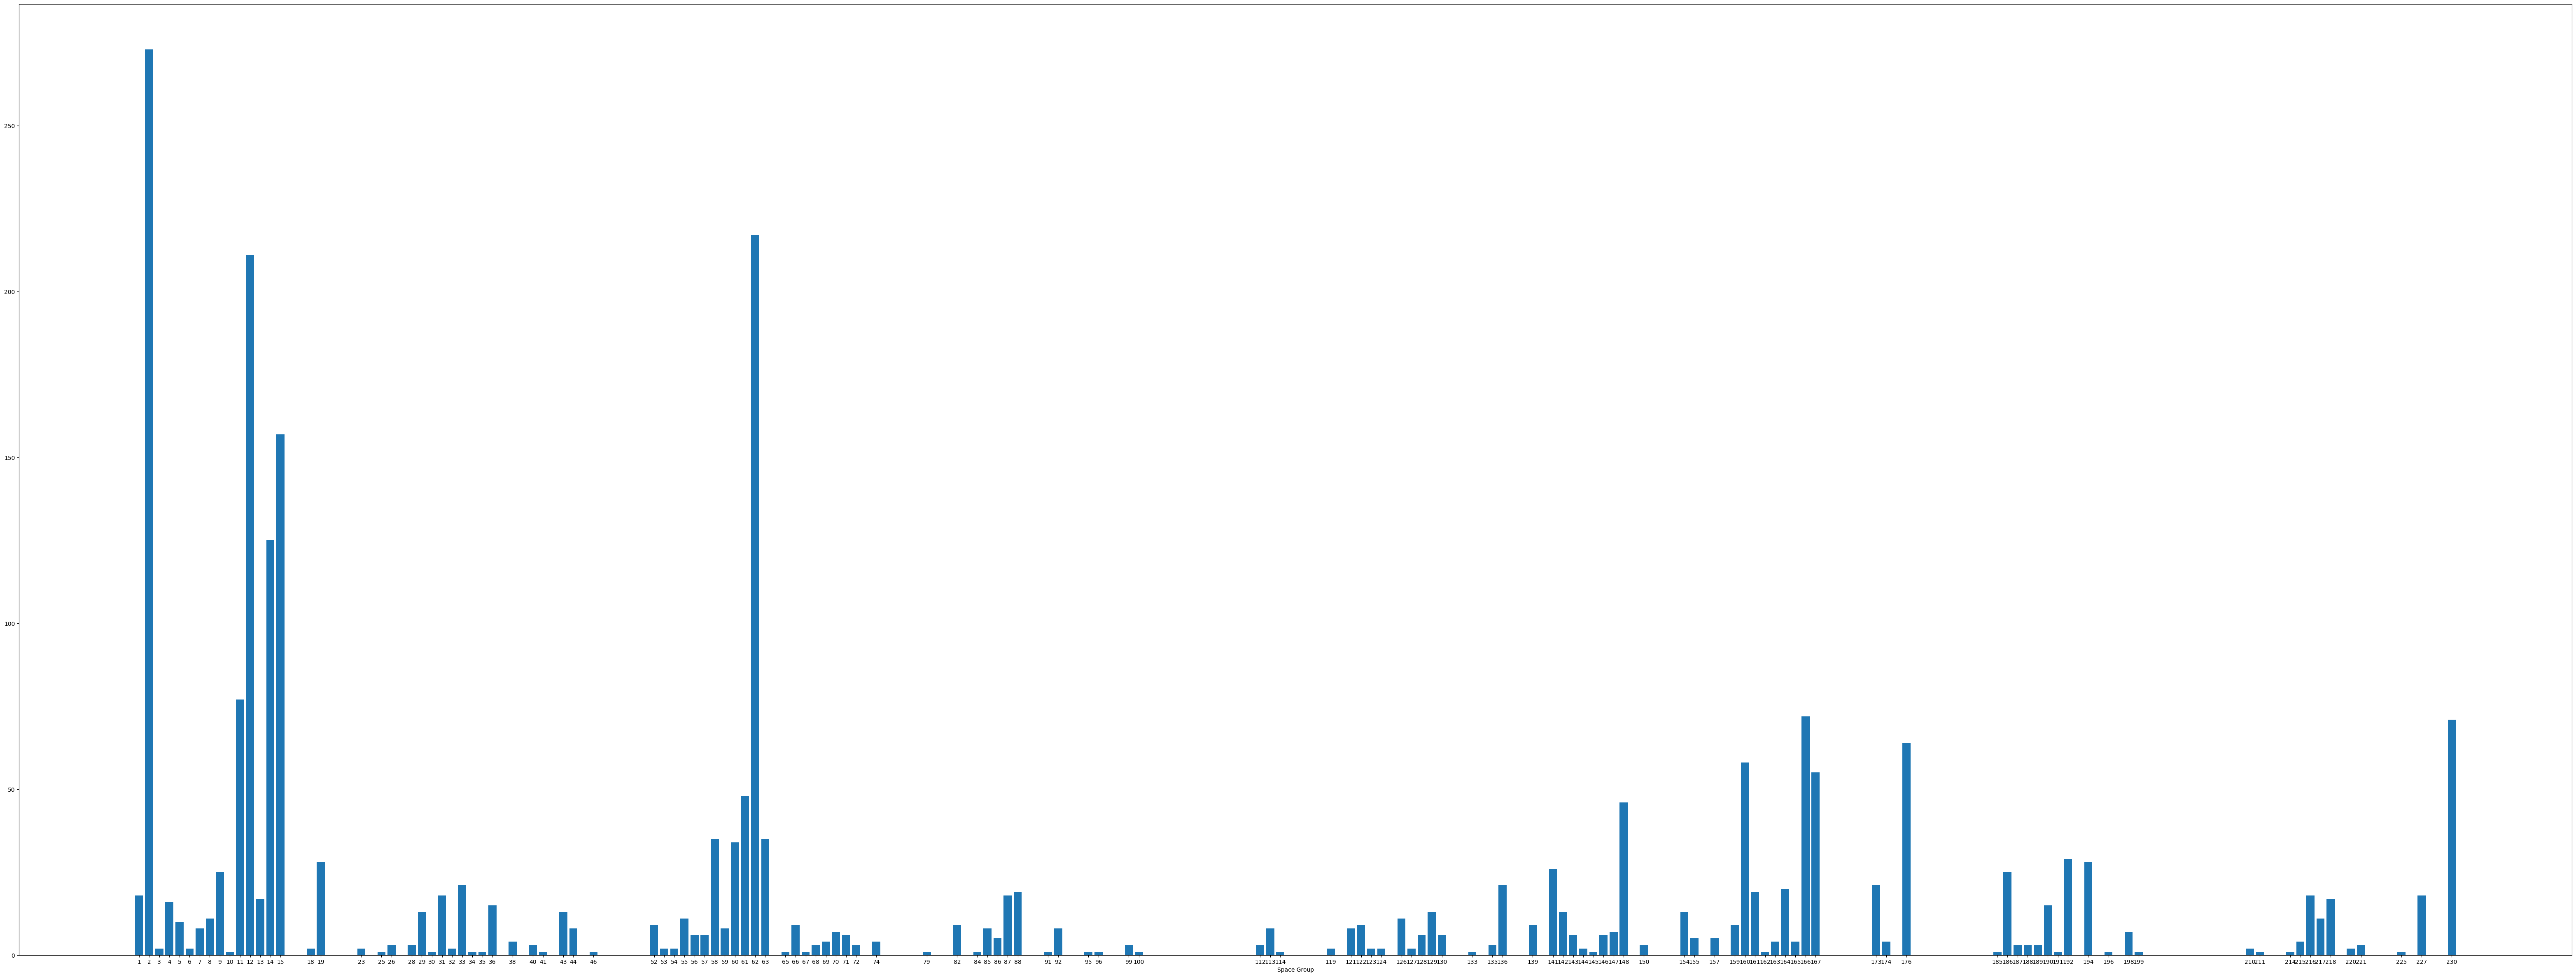

In [29]:
        
sgdict = Counter(standardSG_Num)
plt.figure(figsize=(80,30))
#plt.yscale('log')
bars =plt.bar(sgdict.keys(),sgdict.values())
values = list(sgdict.values())
plt.xticks(ticks=list(sgdict.keys()))
plt.xlabel("Space Group")

In [34]:
noneNames = []
noneSG = []
for index,row in RRUFF_df.iterrows():
    if(numpy.isnan(row['Space Group #'])):
        noneNames.append(row['Name'])
        noneSG.append(row["Space Group Symbol"])

In [37]:
failCounter

439

In [36]:
Counter(noneSG)

Counter({'P2_1/a': 95,
         'P2_1/n': 91,
         'Fd3m': 54,
         'Fm3m': 35,
         'Pa3': 21,
         'I2/a': 15,
         'P2_1/b': 14,
         'P2/a': 11,
         'A2/a': 10,
         'Ia3d': 9,
         'I2/m': 8,
         'Im3': 7,
         'Cmca': 5,
         'P2/n': 4,
         'Pn3': 4,
         'Fd3': 4,
         'A2/m': 4,
         'Aa': 4,
         'I2': 3,
         'P2_12_12_': 3,
         'Ia': 3,
         'B2/b': 3,
         'I2/c': 3,
         'Bba2': 3,
         'Im3m': 3,
         'Fd3c': 2,
         'Pn3m': 2,
         'Pm3n': 2,
         'Pa': 2,
         'F2/d': 2,
         'Pn': 2,
         'F2/m': 2,
         'Ia3': 1,
         'Pm3m': 1,
         'B2_1': 1,
         'Acam': 1,
         'Bbcm': 1,
         'Abma': 1,
         'SPACEGROUP#:0': 1,
         'A2': 1,
         'Ccmb': 1})